# STRATOS 2022 uPRISM Open Data Tutorial

This notebook complements the Streamlit flight tracker by showing how to
load, inspect, clean, visualize, validate, and export the **Strato-Science
2022 uPRISM dataset** directly with Python.

The 2022 campaign includes:

- estimation-filter data at 1 Hz and 25 Hz;
- dual-GNSS data at 1 Hz;
- IMU, attitude, temperature, and pressure data at 1 Hz;
- track angle at 1 Hz;
- horizon- and nadir-facing images captured approximately every four minutes.

## Data-quality issues handled

1. Some CSV data rows contain a trailing comma, so header rows and data rows
   may initially have unequal widths.
2. Some records contain GPS-epoch timestamps near 1980.
3. Initial GNSS rows can contain the uninitialized coordinate pair `(0°, 0°)`.
4. A short navigation segment contains a sudden position and ellipsoid-height
   jump before returning to the Timmins-area flight path.
5. The final exported trajectory is the same spatially cleaned dataframe used
   in the final 2D and 3D plots.

Raw observations remain unchanged for traceability. Cleaning is applied only
to derived analysis tables.


In [ ]:
import csv
import io
import math
import re
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import urllib3
from IPython.display import display

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)

pandas: 3.0.3
numpy: 2.4.6


## 1. Campaign configuration

The official readme places the beginning of data near 01:56 UTC on
August 22, 2022. The flight data includes a later power interruption,
so gaps should not automatically be considered parsing errors.

In [2]:
YEAR = 2022
FLIGHT_DATE = "2022-08-22"

DATA_SERVER_ROOT = (
    "https://donnees-data.asc-csa.gc.ca/users/"
    "OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/"
)
BASE_URL = DATA_SERVER_ROOT + "uprism_data_2022/"
IMAGE_BASE_URL = DATA_SERVER_ROOT + "uprism_images_2022/"

FILES = {
    "ef_1hz": ("GQ7_EF_1hz_20220822.csv", "multi"),
    "ef_25hz": ("GQ7_EF_25hz_20220822.csv", "multi"),
    "gnss1": ("GQ7_GNSS1_20220822.csv", "multi"),
    "gnss2": ("GQ7_GNSS2_20220822.csv", "multi"),
    "imu": ("GQ7_IMU_20220822.csv", "multi"),
    "track": ("SWNAV_AHR0_track_angle_20220822.csv", "auto"),
}

POSITION_JUMP_THRESHOLD_M = 100_000
AUTO_SELECT_LARGEST_SEGMENT = True

# The Position Valid bit is retained for inspection. It is not enforced by
# default because the 2022 receiver can report plausible positions during
# initialization while validity information is still changing.
REQUIRE_POSITION_VALID_FLAG = False

FILES


{'ef_1hz': ('GQ7_EF_1hz_20220822.csv', 'multi'),
 'ef_25hz': ('GQ7_EF_25hz_20220822.csv', 'multi'),
 'gnss1': ('GQ7_GNSS1_20220822.csv', 'multi'),
 'gnss2': ('GQ7_GNSS2_20220822.csv', 'multi'),
 'imu': ('GQ7_IMU_20220822.csv', 'multi'),
 'track': ('SWNAV_AHR0_track_angle_20220822.csv', 'auto')}

## 2. Robust CSV-loading helpers

In [3]:
def normalize_name(value: object) -> str:
    """Normalize a label for loose column matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


def make_unique(names: list[object]) -> list[str]:
    """Make duplicate or blank header names usable as dataframe columns."""
    counts: dict[str, int] = {}
    output: list[str] = []

    for value in names:
        name = str(value).strip() or "unnamed"
        count = counts.get(name, 0)
        output.append(name if count == 0 else f"{name}_{count}")
        counts[name] = count + 1

    return output


def fetch_text(url: str, timeout: int = 180) -> str:
    """Download a text file from the CSA open-data server."""
    response = requests.get(
        url,
        timeout=timeout,
        verify=False,
        headers={"User-Agent": "STRATOS-uPRISM-tutorial"},
    )
    response.raise_for_status()
    return response.content.decode("utf-8-sig", errors="replace")


def _trim_trailing_empty_fields(row: list[str]) -> list[str]:
    """Remove only empty fields created by trailing delimiters."""
    cleaned = [str(value).strip() for value in row]
    while cleaned and cleaned[-1] == "":
        cleaned.pop()
    return cleaned


def read_uprism_table(
    url: str,
    *,
    header_mode: str = "auto",
) -> pd.DataFrame:
    """Read a uPRISM CSV without shifting columns.

    Some 2022 files have fewer header fields than raw data fields because each
    data row ends with an extra comma. Trailing empty fields are removed before
    alignment. Any remaining extra non-empty fields raise an error rather than
    being silently discarded.
    """
    text = fetch_text(url)

    if header_mode == "none":
        frame = pd.DataFrame({"raw_text": text.splitlines()})
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    parsed_rows = [
        _trim_trailing_empty_fields(row)
        for row in csv.reader(io.StringIO(text))
    ]
    parsed_rows = [row for row in parsed_rows if any(row)]

    if not parsed_rows:
        frame = pd.DataFrame()
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    if header_mode == "single":
        header_index = 0
    elif header_mode == "multi":
        header_index = 1
    elif header_mode == "auto":
        first = {normalize_name(value) for value in parsed_rows[0]}
        second = (
            {normalize_name(value) for value in parsed_rows[1]}
            if len(parsed_rows) > 1
            else set()
        )
        required = {"source", "utctimestamp"}

        if required.issubset(first):
            header_index = 0
        elif required.issubset(second):
            header_index = 1
        else:
            keywords = {
                "source",
                "utctimestamp",
                "packet",
                "latitude",
                "longitude",
                "trackangle",
                "trackanglevalid",
            }
            first_score = len(first.intersection(keywords))
            second_score = len(second.intersection(keywords))
            header_index = 0 if first_score >= second_score else 1
    else:
        raise ValueError(f"Unsupported header_mode: {header_mode}")

    header = make_unique(parsed_rows[header_index])
    width = len(header)

    data_rows: list[list[str]] = []

    for source_row, row in enumerate(
        parsed_rows[header_index + 1:],
        start=header_index + 2,
    ):
        if len(row) < width:
            row = row + [""] * (width - len(row))
        elif len(row) > width:
            raise ValueError(
                "A data row contains more non-empty fields than the header. "
                f"Source row: {source_row}; header width: {width}; "
                f"row width: {len(row)}."
            )
        data_rows.append(row)

    frame = pd.DataFrame(data_rows, columns=header)
    frame.attrs["source_url"] = url
    frame.attrs["header_rows"] = header_index + 1
    return frame


def find_column(
    frame: pd.DataFrame,
    candidates: list[str],
    *,
    required: bool = False,
) -> str | None:
    """Find a column by normalized exact match, then contains match."""
    normalized_to_actual = {
        normalize_name(column): column
        for column in frame.columns
    }

    for candidate in candidates:
        normalized = normalize_name(candidate)
        if normalized in normalized_to_actual:
            return normalized_to_actual[normalized]

    for candidate in candidates:
        normalized = normalize_name(candidate)
        for column in frame.columns:
            if normalized and normalized in normalize_name(column):
                return column

    if required:
        raise KeyError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns: {list(frame.columns)}"
        )
    return None


def numeric(series: pd.Series) -> pd.Series:
    """Convert a series to numeric values, coercing failures to NaN."""
    return pd.to_numeric(series, errors="coerce")


def parse_campaign_timestamp(
    series: pd.Series,
    *,
    flight_date: str,
) -> pd.Series:
    """Parse complete UTC timestamps and time-only values."""
    raw = series.astype(str).str.strip()
    parsed = pd.to_datetime(raw, utc=True, errors="coerce")

    time_only_mask = raw.str.match(
        r"^\d{1,2}:\d{2}(?::\d{2}(?:[.,]\d+)?)?Z?$",
        na=False,
    )
    if not time_only_mask.any():
        return parsed

    base_date = pd.Timestamp(flight_date, tz="UTC").normalize()
    day_offset = 0
    previous_seconds: float | None = None

    for index in raw[time_only_mask].index:
        value = raw.loc[index].rstrip("Z").replace(",", ".")

        if len(value.split(":")) == 2:
            value = f"{value}:00"

        delta = pd.to_timedelta(value, errors="coerce")
        if pd.isna(delta):
            parsed.loc[index] = pd.NaT
            continue

        seconds = float(delta.total_seconds())

        if (
            previous_seconds is not None
            and seconds < previous_seconds - 6 * 3600
        ):
            day_offset += 1

        parsed.loc[index] = (
            base_date
            + pd.Timedelta(days=day_offset)
            + delta
        )
        previous_seconds = seconds

    return parsed


def missing_value_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """Summarize both NaN values and blank strings."""
    normalized = frame.replace(r"^\s*$", np.nan, regex=True)

    summary = pd.DataFrame(
        {
            "column": normalized.columns,
            "missing_rows": [
                int(normalized[column].isna().sum())
                for column in normalized.columns
            ],
            "missing_percent": [
                float(normalized[column].isna().mean() * 100)
                for column in normalized.columns
            ],
        }
    )

    return (
        summary
        .sort_values(
            ["missing_percent", "missing_rows"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def standardize_trajectory(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    require_position_valid_flag: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return complete diagnostics and an initially cleaned trajectory."""
    time_col = find_column(
        frame,
        ["UTC Timestamp", "Timestamp", "Time"],
        required=True,
    )
    lat_col = find_column(frame, ["Latitude", "Lat"], required=True)
    lon_col = find_column(
        frame,
        ["Longitude", "Lon", "Long"],
        required=True,
    )
    altitude_col = find_column(
        frame,
        ["Ellipsoid Height", "Altitude", "MSL Height"],
        required=False,
    )
    position_valid_col = find_column(
        frame,
        ["Position Valid"],
        required=False,
    )

    diagnostics = frame.copy()

    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["latitude_numeric"] = numeric(diagnostics[lat_col])
    diagnostics["longitude_numeric"] = numeric(diagnostics[lon_col])
    diagnostics["altitude_numeric"] = (
        numeric(diagnostics[altitude_col])
        if altitude_col is not None
        else np.nan
    )

    diagnostics["timestamp_year"] = diagnostics["parsed_timestamp"].dt.year
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )
    diagnostics["coordinate_in_range"] = (
        diagnostics["latitude_numeric"].between(-90, 90)
        & diagnostics["longitude_numeric"].between(-180, 180)
    )
    diagnostics["nonzero_coordinate"] = ~(
        (diagnostics["latitude_numeric"] == 0)
        & (diagnostics["longitude_numeric"] == 0)
    )

    if position_valid_col is not None:
        position_valid_value = (
            numeric(diagnostics[position_valid_col])
            .fillna(0)
            .astype("int64")
        )
        diagnostics["lat_lon_valid_flag"] = (
            (position_valid_value & 1) == 1
        )
    else:
        diagnostics["lat_lon_valid_flag"] = True

    validity = (
        diagnostics["parsed_timestamp"].notna()
        & diagnostics["expected_year"]
        & diagnostics["coordinate_in_range"]
        & diagnostics["nonzero_coordinate"]
    )

    if require_position_valid_flag:
        validity &= diagnostics["lat_lon_valid_flag"]

    diagnostics["trajectory_row_valid"] = validity

    cleaned = diagnostics.loc[
        diagnostics["trajectory_row_valid"],
        [
            "original_data_index",
            "original_csv_row",
            "parsed_timestamp",
            "latitude_numeric",
            "longitude_numeric",
            "altitude_numeric",
            "lat_lon_valid_flag",
        ],
    ].copy()

    cleaned.columns = [
        "original_data_index",
        "original_csv_row",
        "timestamp",
        "latitude",
        "longitude",
        "altitude_m",
        "lat_lon_valid_flag",
    ]

    cleaned = cleaned.sort_values("timestamp").reset_index(drop=True)
    return diagnostics, cleaned


EARTH_RADIUS_M = 6_371_000


def haversine_step_m(
    latitude: pd.Series,
    longitude: pd.Series,
) -> pd.Series:
    """Calculate distance from each row to its preceding row."""
    lat1 = np.radians(latitude.shift(1))
    lon1 = np.radians(longitude.shift(1))
    lat2 = np.radians(latitude)
    lon2 = np.radians(longitude)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return pd.Series(
        2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a)),
        index=latitude.index,
    )


def detect_altitude_discontinuities(
    diagnostics: pd.DataFrame,
    *,
    step_threshold_m: float = 1000,
    rate_threshold_mps: float = 100,
    rolling_window: int = 11,
    residual_threshold_m: float = 1500,
    max_temporary_segment_samples: int = 20,
    neighbor_tolerance_m: float = 1000,
    max_gap_seconds: float = 10,
) -> pd.DataFrame:
    """Detect abrupt local altitude changes without using global IQR."""
    work = diagnostics.copy().reset_index(drop=True)
    altitude = numeric(work["altitude_numeric"])
    timestamp = pd.to_datetime(
        work["parsed_timestamp"],
        utc=True,
        errors="coerce",
    )

    time_step_s = timestamp.diff().dt.total_seconds()
    valid_consecutive_step = (
        time_step_s.gt(0)
        & time_step_s.le(max_gap_seconds)
    )

    altitude_step_m = altitude.diff().where(valid_consecutive_step)
    altitude_rate_mps = (
        altitude_step_m
        / time_step_s.where(valid_consecutive_step)
    )

    rolling_median = altitude.rolling(
        rolling_window,
        center=True,
        min_periods=3,
    ).median()
    local_residual = (altitude - rolling_median).abs()

    transition = (
        altitude_step_m.abs().ge(step_threshold_m)
        | altitude_rate_mps.abs().ge(rate_threshold_mps)
    ).fillna(False)

    temporary_segment = pd.Series(
        False,
        index=work.index,
        dtype=bool,
    )

    transition_positions = np.flatnonzero(transition.to_numpy())

    for first, second in zip(
        transition_positions[:-1],
        transition_positions[1:],
    ):
        gap = second - first
        if gap < 1 or gap > max_temporary_segment_samples:
            continue

        before_index = max(first - 1, 0)
        after_index = second

        before_altitude = altitude.iloc[before_index]
        after_altitude = altitude.iloc[after_index]

        if pd.isna(before_altitude) or pd.isna(after_altitude):
            continue

        if abs(after_altitude - before_altitude) <= neighbor_tolerance_m:
            temporary_segment.iloc[first:second + 1] = True

    local_residual_flag = local_residual.ge(
        residual_threshold_m
    ).fillna(False)

    work["time_step_s"] = time_step_s
    work["valid_consecutive_step"] = valid_consecutive_step
    work["altitude_step_m"] = altitude_step_m
    work["altitude_rate_mps"] = altitude_rate_mps
    work["rolling_altitude_median_m"] = rolling_median
    work["local_altitude_residual_m"] = local_residual
    work["sudden_altitude_transition"] = transition
    work["temporary_altitude_segment"] = temporary_segment
    work["local_altitude_disagreement"] = local_residual_flag
    work["altitude_anomaly_candidate"] = (
        transition | temporary_segment
    )

    return work


def segment_trajectory_by_position_jump(
    trajectory: pd.DataFrame,
    *,
    threshold_m: float,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split a trajectory whenever consecutive positions differ too much."""
    segmented = trajectory.copy()

    segmented["position_step_m"] = haversine_step_m(
        segmented["latitude"],
        segmented["longitude"],
    )
    segmented["new_segment"] = (
        segmented["position_step_m"] > threshold_m
    ).fillna(False)
    segmented["segment_id"] = segmented["new_segment"].cumsum()

    summary = (
        segmented
        .groupby("segment_id", as_index=False)
        .agg(
            rows=("segment_id", "size"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            minimum_latitude=("latitude", "min"),
            maximum_latitude=("latitude", "max"),
            minimum_longitude=("longitude", "min"),
            maximum_longitude=("longitude", "max"),
            minimum_altitude=("altitude_m", "min"),
            maximum_altitude=("altitude_m", "max"),
        )
        .sort_values("rows", ascending=False)
        .reset_index(drop=True)
    )

    return segmented, summary


def plot_2d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty:
        print("No trajectory rows are available.")
        return

    plt.figure(figsize=(10, 7))
    plt.plot(
        trajectory["longitude"],
        trajectory["latitude"],
        linewidth=1,
    )
    plt.scatter(
        trajectory["longitude"].iloc[0],
        trajectory["latitude"].iloc[0],
        label="Start",
    )
    plt.scatter(
        trajectory["longitude"].iloc[-1],
        trajectory["latitude"].iloc[-1],
        label="End",
    )
    plt.xlabel("Longitude [degrees]")
    plt.ylabel("Latitude [degrees]")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_3d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty or trajectory["altitude_m"].notna().sum() == 0:
        print("No altitude-enabled trajectory is available.")
        return

    try:
        import plotly.graph_objects as go
    except ImportError:
        print("Install Plotly with: %pip install plotly")
        return

    max_points = 15_000
    step = max(1, math.ceil(len(trajectory) / max_points))
    plot_frame = trajectory.iloc[::step]

    figure = go.Figure(
        data=[
            go.Scatter3d(
                x=plot_frame["longitude"],
                y=plot_frame["latitude"],
                z=plot_frame["altitude_m"],
                mode="lines",
                line={"width": 4},
                name="Flight path",
            )
        ]
    )

    figure.update_layout(
        title=title,
        scene={
            "xaxis_title": "Longitude [degrees]",
            "yaxis_title": "Latitude [degrees]",
            "zaxis_title": "Altitude [m]",
        },
        height=700,
    )
    figure.show()


## 3. Load the core 2022 files

`LOAD_ALL_FILES = False` loads only the files needed for the main
tutorial. Change it to `True` to download the additional EF and GNSS
files.

In [4]:
LOAD_ALL_FILES = False

keys_to_load = ["gnss1", "imu", "track"]
if LOAD_ALL_FILES:
    keys_to_load = list(FILES)

tables: dict[str, pd.DataFrame] = {}

for key in keys_to_load:
    filename, header_mode = FILES[key]
    url = urljoin(BASE_URL, filename)

    print(f"Loading {key}: {filename}")

    tables[key] = read_uprism_table(
        url,
        header_mode=header_mode,
    )

    print("  shape:", tables[key].shape)
    print("  header rows:", tables[key].attrs.get("header_rows"))

gnss1 = tables["gnss1"]
imu = tables["imu"]
track = tables["track"]


Loading gnss1: GQ7_GNSS1_20220822.csv
  shape: (45193, 53)
  header rows: 2
Loading imu: GQ7_IMU_20220822.csv
  shape: (45158, 26)
  header rows: 2
Loading track: SWNAV_AHR0_track_angle_20220822.csv
  shape: (45185, 5)
  header rows: 1


## 4. Inspect the raw tables and headers

In [5]:
for key, frame in tables.items():
    print("\n" + "=" * 100)
    print(key, frame.shape)
    print("Columns:")
    print(list(frame.columns))
    display(frame.head(8))


gnss1 (45193, 53)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Latitude', 'Longitude', 'Ellipsoid Height', 'MSL Height', 'Horizontal Accuracy', 'Vertical Accuracy', 'Position Valid', 'North Velocity', 'East Velocity', 'Down Velocity', 'Speed', 'Ground Speed', 'Heading', 'Speed Accuracy', 'Heading Accuracy', 'NED VEL VALID', 'gdop', 'pdop', 'hdop', 'vdop', 'tdop', 'ndop', 'rdop', 'dop valid', 'Year', 'Month', 'Day', 'Hour', 'Min', 'Sec', 'Mili', 'UTC Valid', 'TOW', 'Week Num', 'GPS Time Valid Flag', 'Bias', 'Drift', 'Bias Accuracy', 'Drift Accuracy', 'Clock Info 2 Valid', 'Fix Type', 'Num Sats', 'Fix Flag', 'Fix Valid', 'Hardware State', 'Antenna State', 'Antenna Power', 'Hardware Valid', 'Leap Seconds', 'Leap Seconds Valid']


,Source,UTC Timestamp,Packet,Latitude,Longitude,Ellipsoid Height,MSL Height,Horizontal Accuracy,Vertical Accuracy,Position Valid,North Velocity,East Velocity,Down Velocity,Speed,Ground Speed,Heading,Speed Accuracy,Heading Accuracy,NED VEL VALID,gdop,pdop,hdop,vdop,tdop,ndop,rdop,dop valid,Year,Month,Day,Hour,Min,Sec,Mili,UTC Valid,TOW,Week Num,GPS Time Valid Flag,Bias,Drift,Bias Accuracy,Drift Accuracy,Clock Info 2 Valid,Fix Type,Num Sats,Fix Flag,Fix Valid,Hardware State,Antenna State,Antenna Power,Hardware Valid,Leap Seconds,Leap Seconds Valid
0,LOGQ7,2022-08-22 01:56:02.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,2,499,0,93380.49999652,2224,3,3.48e-06,5.000000000000001e-07,0.020000002000000003,4.014004e-06,0,4,0,0,7,1,4,1,7,18,0
1,LOGQ7,2022-08-22 01:56:03.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,3,499,0,93381.499996019,2224,3,3.9810000000000005e-06,5.01e-07,0.020000002000000003,4.013996e-06,0,4,0,0,7,1,4,1,7,18,0
2,LOGQ7,2022-08-22 01:56:04.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,4,499,0,93382.499995518,2224,3,4.4820000000000005e-06,5.01e-07,0.020000002000000003,4.014011e-06,0,4,0,0,7,1,4,1,7,18,0
3,LOGQ7,2022-08-22 01:56:05.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,5,499,0,93383.499995017,2224,3,4.983e-06,5.01e-07,0.020000002000000003,4.014007e-06,0,4,0,0,7,1,4,1,7,18,0
4,LOGQ7,2022-08-22 01:56:06.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,6,499,0,93384.499994516,2224,3,5.484e-06,5.01e-07,0.020000002000000003,4.013921e-06,0,4,0,0,7,1,4,1,7,18,0
5,LOGQ7,2022-08-22 01:56:07.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,7,499,0,93385.499994014,2224,3,5.986000000000001e-06,5.01e-07,0.020000002000000003,4.014017e-06,0,4,0,0,7,1,4,1,7,18,0
6,LOGQ7,2022-08-22 01:56:08.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,8,499,0,93386.499993513,2224,3,6.487000000000001e-06,5.02e-07,0.020000002000000003,4.014081e-06,0,4,0,0,7,1,4,1,7,18,0
7,LOGQ7,2022-08-22 01:56:09.500,GQ7_GNSS1,0.0,0.0,0.0,-17.0,4294967.5,1.2921373139539138e-41,0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,180.0,0,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,99.98999786376953,0,2022,8,22,1,56,9,499,0,93387.499993011,2224,3,6.989e-06,5.02e-07,0.020000002000000003,4.014013e-06,0,4,0,0,7,1,4,1,7,18,0



imu (45158, 26)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Scaled Accel X', 'Scaled Accel Y', 'Scaled Accel Z', 'Scaled Gyro X', 'Scaled Gyro Y', 'Scaled Gyro Z', 'Scaled Magnetometer X', 'Scaled Magnetometer Y', 'Scaled Magnetometer Z', 'CF q0', 'CF q1', 'CF q2', 'CF q3', 'CF Roll', 'CF Pitch', 'CF Yaw', 'GPS TOW', 'GPS Week Num', 'GPS Time Valid', 'Min Temp', 'Max Temp', 'Mean Temp', 'Pressure']


,Source,UTC Timestamp,Packet,Scaled Accel X,Scaled Accel Y,Scaled Accel Z,Scaled Gyro X,Scaled Gyro Y,Scaled Gyro Z,Scaled Magnetometer X,Scaled Magnetometer Y,Scaled Magnetometer Z,CF q0,CF q1,CF q2,CF q3,CF Roll,CF Pitch,CF Yaw,GPS TOW,GPS Week Num,GPS Time Valid,Min Temp,Max Temp,Mean Temp,Pressure
0,LOGQ7,2022-08-22 01:56:26.763,GQ7_IMU,-0.010106542147696018,0.011819949373602867,-1.0009896755218506,-0.00018240261124446988,9.314973794971593e-06,4.4944223191123456e-05,-0.03749338537454605,-0.007254735101014376,0.5939862132072449,0.9998993873596191,0.006756606977432966,0.004910432733595371,-0.011467888019979,-0.7806858196556973,-0.5537670851905984,1.317970591161997,93404.763,2224,3,31.961326599121094,32.734806060791016,32.07182312011719,986.9036865234375
1,LOGQ7,2022-08-22 01:56:27.763,GQ7_IMU,-0.010045385919511318,0.01181273814290762,-1.0009819269180298,-0.00015212806465569884,3.19870378007181e-06,3.7250258174026385e-05,-0.03837752342224121,-0.006111132446676493,0.5932166576385498,0.9996922612190247,0.006720053032040596,0.00500653637573123,-0.023349789902567863,-0.7832815049837136,-0.5555581955787284,2.679823653637445,93405.763000763,2224,3,31.961326599121094,32.734806060791016,32.18231964111328,986.930419921875
2,LOGQ7,2022-08-22 01:56:28.763,GQ7_IMU,-0.010059274733066559,0.011752906255424023,-1.0009537935256958,-0.00016159621009137481,2.689869461391936e-06,-1.8462036678101867e-05,-0.03832046687602997,-0.007276755291968584,0.5933066606521606,0.9998957514762878,0.006783686112612486,0.0049579571932554245,-0.01174972578883171,-0.7840093470171432,-0.558956054608251,1.3503223157742914,93406.763000763,2224,3,31.961326599121094,32.734806060791016,32.18231964111328,986.9346313476562
3,LOGQ7,2022-08-22 01:56:29.763,GQ7_IMU,-0.010093403980135918,0.011804775334894657,-1.0010054111480713,-0.0001531422749394551,-6.471225788118318e-06,-1.8151829863199964e-05,-0.03722892701625824,-0.006933830212801695,0.5927778482437134,0.9998503923416138,0.006761901546269655,0.0049925558269023895,-0.015116920694708824,-0.7834512458567591,-0.5603146219228489,1.7362296047055985,93407.763000763,2224,3,31.961326599121094,32.734806060791016,32.292816162109375,986.9360961914062
4,LOGQ7,2022-08-22 01:56:30.763,GQ7_IMU,-0.010133149102330208,0.01179536059498787,-1.0010513067245483,-0.00013494366430677474,0.0001165938374469988,-4.8890229663811624e-05,-0.03623638674616814,-0.006900529842823744,0.5930925607681274,0.999906599521637,0.006785375066101551,0.004927108064293861,-0.010792924091219902,-0.7836292043011497,-0.5561689639009156,1.2406489010543387,93408.763000763,2224,3,31.961326599121094,32.734806060791016,32.292816162109375,986.89501953125
5,LOGQ7,2022-08-22 01:56:31.763,GQ7_IMU,-0.01007886417210102,0.011803016066551208,-1.001033067703247,-0.00015109214291442186,5.609178515442181e-06,4.179513416602276e-05,-0.03683987632393837,-0.006762390490621328,0.5930401086807251,0.9997783303260803,0.0067618535831570625,0.005007230676710606,-0.01929866336286068,-0.7858148114747008,-0.5587144366663619,2.2155105955111516,93409.763000763,2224,3,31.961326599121094,32.734806060791016,32.292816162109375,986.8780517578125
6,LOGQ7,2022-08-22 01:56:32.763,GQ7_IMU,-0.010054918006062508,0.011823954991996288,-1.0010029077529907,-0.00021988122898619622,2.4491532713000197e-06,-1.0210434993496165e-05,-0.03525080904364586,-0.00671445531770587,0.5937613248825073,0.9998335242271423,0.0067849368788301945,0.004992715083062649,-0.016189241781830788,-0.7866914235659896,-0.5594495357757845,1.8591386453765664,93410.763000763,2224,3,31.961326599121094,32.734806060791016,32.292816162109375,986.9209594726562
7,LOGQ7,2022-08-22 01:56:33.763,GQ7_IMU,-0.01006409153342247,0.011815858073532581,-1.0010706186294556,-0.00018193050345871598,9.777844388736412e-05,3.5165194276487455e-05,-0.03714369609951973,-0.006194953341037035,0.5934369564056396,0.9996623992919922,0.0067428830079734325,0.0050352164544165134,-0.024585338309407234,-0.7866641028093097,-0.5578107706226575,2.8214856190049176,93411.763000763,2224,3


track (45185, 5)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Track Angle', 'Track Angle Valid']


,Source,UTC Timestamp,Packet,Track Angle,Track Angle Valid
0,SWNAV,2022-08-22 01:56:00.956,AHR0,345.677,0
1,SWNAV,2022-08-22 01:56:01.956,AHR0,345.677,0
2,SWNAV,2022-08-22 01:56:02.957,AHR0,345.677,0
3,SWNAV,2022-08-22 01:56:03.957,AHR0,345.677,0
4,SWNAV,2022-08-22 01:56:04.958,AHR0,345.677,0
5,SWNAV,2022-08-22 01:56:05.958,AHR0,345.677,0
6,SWNAV,2022-08-22 01:56:06.960,AHR0,345.677,0
7,SWNAV,2022-08-22 01:56:07.959,AHR0,345.677,0


## 5. Dataset inventory

In [6]:
inventory = pd.DataFrame(
    [
        {
            "dataset": key,
            "rows": len(frame),
            "columns": len(frame.columns),
            "header_rows": frame.attrs.get("header_rows"),
            "source_url": frame.attrs.get("source_url"),
            "first_columns": ", ".join(map(str, frame.columns[:8])),
        }
        for key, frame in tables.items()
    ]
)
display(inventory)


,dataset,rows,columns,header_rows,source_url,first_columns
0,gnss1,45193,53,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2022/GQ7_GNSS1_202...,"Source, UTC Timestamp, Packet, Latitude, Longitude, Ellipsoid Height, MSL Height, Horizontal Accuracy"
1,imu,45158,26,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2022/GQ7_IMU_20220...,"Source, UTC Timestamp, Packet, Scaled Accel X, Scaled Accel Y, Scaled Accel Z, Scaled Gyro X, Scaled Gyro Y"
2,track,45185,5,1,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2022/SWNAV_AHR0_tr...,"Source, UTC Timestamp, Packet, Track Angle, Track Angle Valid"


## 6. Timestamp validation

The raw rows are preserved. The cleaned trajectory later excludes
timestamps outside 2022, but this section first displays all anomalies
so they remain auditable.

In [7]:
diagnostics_2022, trajectory_2022_initial = standardize_trajectory(
    gnss1,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
    require_position_valid_flag=REQUIRE_POSITION_VALID_FLAG,
)

year_counts_2022 = (
    diagnostics_2022["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)
display(year_counts_2022)

rows_outside_2022 = diagnostics_2022[
    diagnostics_2022["parsed_timestamp"].notna()
    & ~diagnostics_2022["expected_year"]
].copy()

print("Rows with timestamp years outside 2022:", len(rows_outside_2022))

columns_to_show = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "timestamp_year",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "lat_lon_valid_flag",
]

for candidate in [
    "UTC Timestamp",
    "Position Valid",
    "UTC Valid",
    "GPS Time Valid",
    "GPS Time Valid Flag",
    "GPS Week Num",
    "TOW",
    "Fix Type",
    "Num Sats",
    "Fix Valid",
]:
    column = find_column(
        diagnostics_2022,
        [candidate],
        required=False,
    )
    if column is not None and column not in columns_to_show:
        columns_to_show.append(column)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(
        rows_outside_2022[columns_to_show]
        .sort_values("parsed_timestamp")
    )


,year,rows
0,1980,9
1,2022,45184


Rows with timestamp years outside 2022: 9


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44825,44825,44828,1980-01-06 00:00:03.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:03.500,0,0,0,3.5,4,0,7
44826,44826,44829,1980-01-06 00:00:04.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
44827,44827,44830,1980-01-06 00:00:05.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:05.500,0,0,0,5.499999588,4,0,7
44828,44828,44831,1980-01-06 00:00:06.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.500,0,0,0,6.49999902,4,0,7
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7
44830,44830,44833,1980-01-07 15:04:17.752000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:17.752,0,0,1,140657.75199971301,4,0,7
44831,44831,44834,1980-01-07 15:04:18.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:18.500,0,0,1,140658.499999283,4,0,7
44832,44832,44835,1980-01-07 15:04:19.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:19.500,0,0,1,140659.499998707,4,0,7
44833,44833,44836,1980-01-07 15:04:20.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:20.500,0,0,1,140660.499998128,4,0,7


### Inspect the rows surrounding each timestamp anomaly

In [8]:
for anomaly_index in rows_outside_2022.index:
    start = max(0, anomaly_index - 4)
    end = min(len(diagnostics_2022) - 1, anomaly_index + 4)

    print("\n" + "=" * 110)
    print(
        "Context around source CSV row",
        diagnostics_2022.loc[
            anomaly_index,
            "original_csv_row",
        ],
    )

    display(
        diagnostics_2022.loc[
            start:end,
            columns_to_show,
        ]
    )



Context around source CSV row 44828


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44821,44821,44824,2022-08-22 14:23:03.500000+00:00,2022,48.708361,-82.879000,36266.318,True,2022-08-22 14:23:03.500,16713,3,3,138201.499983152,0,29,7
44822,44822,44825,2022-08-22 14:23:04.500000+00:00,2022,48.708473,-82.879107,36267.143,True,2022-08-22 14:23:04.500,16713,3,3,138202.499982533,0,29,7
44823,44823,44826,2022-08-22 14:23:05.500000+00:00,2022,48.708586,-82.879215,36267.962,True,2022-08-22 14:23:05.500,16713,3,3,138203.499981913,0,29,7
44824,44824,44827,2022-08-22 14:23:06.500000+00:00,2022,48.708698,-82.879323,36268.739,True,2022-08-22 14:23:06.500,16713,3,3,138204.499981293,0,29,7
44825,44825,44828,1980-01-06 00:00:03.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,4,0,7
44826,44826,44829,1980-01-06 00:00:04.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
44827,44827,44830,1980-01-06 00:00:05.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.500,0,0,0,5.499999588,4,0,7
44828,44828,44831,1980-01-06 00:00:06.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:06.500,0,0,0,6.49999902,4,0,7
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7



Context around source CSV row 44829


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44822,44822,44825,2022-08-22 14:23:04.500000+00:00,2022,48.708473,-82.879107,36267.143,True,2022-08-22 14:23:04.500,16713,3,3,138202.499982533,0,29,7
44823,44823,44826,2022-08-22 14:23:05.500000+00:00,2022,48.708586,-82.879215,36267.962,True,2022-08-22 14:23:05.500,16713,3,3,138203.499981913,0,29,7
44824,44824,44827,2022-08-22 14:23:06.500000+00:00,2022,48.708698,-82.879323,36268.739,True,2022-08-22 14:23:06.500,16713,3,3,138204.499981293,0,29,7
44825,44825,44828,1980-01-06 00:00:03.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,4,0,7
44826,44826,44829,1980-01-06 00:00:04.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
44827,44827,44830,1980-01-06 00:00:05.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.500,0,0,0,5.499999588,4,0,7
44828,44828,44831,1980-01-06 00:00:06.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:06.500,0,0,0,6.49999902,4,0,7
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7
44830,44830,44833,1980-01-07 15:04:17.752000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-07 15:04:17.752,0,0,1,140657.75199971301,4,0,7



Context around source CSV row 44830


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44823,44823,44826,2022-08-22 14:23:05.500000+00:00,2022,48.708586,-82.879215,36267.962,True,2022-08-22 14:23:05.500,16713,3,3,138203.499981913,0,29,7
44824,44824,44827,2022-08-22 14:23:06.500000+00:00,2022,48.708698,-82.879323,36268.739,True,2022-08-22 14:23:06.500,16713,3,3,138204.499981293,0,29,7
44825,44825,44828,1980-01-06 00:00:03.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:03.500,0,0,0,3.5,4,0,7
44826,44826,44829,1980-01-06 00:00:04.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7
44827,44827,44830,1980-01-06 00:00:05.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:05.500,0,0,0,5.499999588,4,0,7
44828,44828,44831,1980-01-06 00:00:06.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:06.500,0,0,0,6.49999902,4,0,7
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7
44830,44830,44833,1980-01-07 15:04:17.752000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-07 15:04:17.752,0,0,1,140657.75199971301,4,0,7
44831,44831,44834,1980-01-07 15:04:18.500000+00:00,1980,0.000000,0.000000,0.000,False,1980-01-07 15:04:18.500,0,0,1,140658.499999283,4,0,7


... (8 outputs left out)


Context around source CSV row 44835


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44828,44828,44831,1980-01-06 00:00:06.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:06.500,0,0,0,6.49999902,4,0,7
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7
44830,44830,44833,1980-01-07 15:04:17.752000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:17.752,0,0,1,140657.75199971301,4,0,7
44831,44831,44834,1980-01-07 15:04:18.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:18.500,0,0,1,140658.499999283,4,0,7
44832,44832,44835,1980-01-07 15:04:19.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:19.500,0,0,1,140659.499998707,4,0,7
44833,44833,44836,1980-01-07 15:04:20.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:20.500,0,0,1,140660.499998128,4,0,7
44834,44834,44837,2022-08-22 15:04:03.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:03.500,0,0,3,140661.499997548,4,0,7
44835,44835,44838,2022-08-22 15:04:04.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:04.500,0,0,3,140662.499996966,4,0,7
44836,44836,44839,2022-08-22 15:04:05.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:05.500,0,0,3,140663.499996383,4,0,7



Context around source CSV row 44836


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
44829,44829,44832,1980-01-06 00:00:07.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:07.500,0,0,0,7.499998449,4,0,7
44830,44830,44833,1980-01-07 15:04:17.752000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:17.752,0,0,1,140657.75199971301,4,0,7
44831,44831,44834,1980-01-07 15:04:18.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:18.500,0,0,1,140658.499999283,4,0,7
44832,44832,44835,1980-01-07 15:04:19.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:19.500,0,0,1,140659.499998707,4,0,7
44833,44833,44836,1980-01-07 15:04:20.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-07 15:04:20.500,0,0,1,140660.499998128,4,0,7
44834,44834,44837,2022-08-22 15:04:03.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:03.500,0,0,3,140661.499997548,4,0,7
44835,44835,44838,2022-08-22 15:04:04.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:04.500,0,0,3,140662.499996966,4,0,7
44836,44836,44839,2022-08-22 15:04:05.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:05.500,0,0,3,140663.499996383,4,0,7
44837,44837,44840,2022-08-22 15:04:06.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 15:04:06.500,0,0,3,140664.499995797,4,0,7


## 7. Missing-value inspection

Missing values are summarized without automatically removing columns.

In [9]:
display(missing_value_summary(gnss1).head(30))

,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,Latitude,0,0.0
4,Longitude,0,0.0
5,Ellipsoid Height,0,0.0
6,MSL Height,0,0.0
7,Horizontal Accuracy,0,0.0
8,Vertical Accuracy,0,0.0
9,Position Valid,0,0.0


## 8. Coordinate validation

The first GNSS records can contain `(0°, 0°)`, which is a common
uninitialized placeholder rather than a Timmins flight position.

In [10]:
coordinate_quality = pd.DataFrame(
    {
        "check": [
            "total rows",
            "timestamps in 2022",
            "coordinates in geographic range",
            "nonzero coordinates",
            "rows with latitude/longitude valid bit",
            "initial cleaned trajectory rows",
        ],
        "rows": [
            len(diagnostics_2022),
            int(diagnostics_2022["expected_year"].sum()),
            int(diagnostics_2022["coordinate_in_range"].sum()),
            int(diagnostics_2022["nonzero_coordinate"].sum()),
            int(diagnostics_2022["lat_lon_valid_flag"].sum()),
            len(trajectory_2022_initial),
        ],
    }
)
display(coordinate_quality)

zero_coordinates = diagnostics_2022[
    ~diagnostics_2022["nonzero_coordinate"]
]

print("Rows at (0°, 0°):", len(zero_coordinates))
display(zero_coordinates[columns_to_show].head(30))

print("Position-validity flag distribution:")
display(
    diagnostics_2022["lat_lon_valid_flag"]
    .value_counts(dropna=False)
    .rename_axis("latitude_longitude_valid")
    .reset_index(name="rows")
)


,check,rows
0,total rows,45193
1,timestamps in 2022,45184
2,coordinates in geographic range,45193
3,nonzero coordinates,45169
4,rows with latitude/longitude valid bit,22360
5,initial cleaned trajectory rows,45169


Rows at (0°, 0°): 24


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid
0,0,3,2022-08-22 01:56:02.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:02.500,0,0,3,93380.49999652,4,0,7
1,1,4,2022-08-22 01:56:03.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:03.500,0,0,3,93381.499996019,4,0,7
2,2,5,2022-08-22 01:56:04.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:04.500,0,0,3,93382.499995518,4,0,7
3,3,6,2022-08-22 01:56:05.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:05.500,0,0,3,93383.499995017,4,0,7
4,4,7,2022-08-22 01:56:06.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:06.500,0,0,3,93384.499994516,4,0,7
5,5,8,2022-08-22 01:56:07.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:07.500,0,0,3,93385.499994014,4,0,7
6,6,9,2022-08-22 01:56:08.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:08.500,0,0,3,93386.499993513,4,0,7
7,7,10,2022-08-22 01:56:09.500000+00:00,2022,0.0,0.0,0.0,False,2022-08-22 01:56:09.500,0,0,3,93387.499993011,4,0,7
44825,44825,44828,1980-01-06 00:00:03.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:03.500,0,0,0,3.5,4,0,7
44826,44826,44829,1980-01-06 00:00:04.500000+00:00,1980,0.0,0.0,0.0,False,1980-01-06 00:00:04.500,0,0,0,4.5,4,0,7


Position-validity flag distribution:


,latitude_longitude_valid,rows
0,False,22833
1,True,22360


## 9. Visualize the initially cleaned trajectory

This plot excludes 1980 timestamps and `(0°, 0°)` coordinates, but it is
shown before spatial discontinuities are removed.


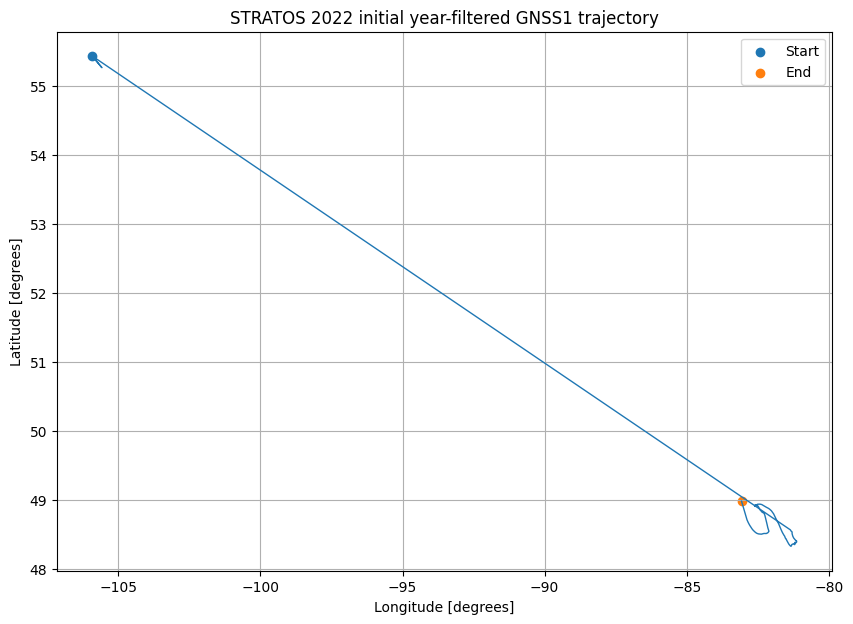

In [11]:
plot_2d_trajectory(
    trajectory_2022_initial,
    title="STRATOS 2022 initial year-filtered GNSS1 trajectory",
)


## 10. Detect sudden ellipsoid-height anomalies correctly

A global IQR rule would incorrectly label the balloon's expected climb
from the ground to the stratosphere. Instead, this tutorial detects
abrupt local discontinuities and short temporary altitude blocks.

The thresholds below are diagnostic parameters, not universal physical
constants. Adjust them after inspecting the sampling interval and
mission context.

In [12]:
altitude_input_2022 = (
    diagnostics_2022[
        diagnostics_2022["parsed_timestamp"].notna()
        & diagnostics_2022["expected_year"]
    ]
    .sort_values("original_data_index")
    .reset_index(drop=True)
)

altitude_diagnostics_2022 = detect_altitude_discontinuities(
    altitude_input_2022,
    step_threshold_m=1000,
    rate_threshold_mps=100,
    rolling_window=11,
    residual_threshold_m=1500,
    max_temporary_segment_samples=20,
    neighbor_tolerance_m=1000,
    max_gap_seconds=10,
)

altitude_candidates_2022 = altitude_diagnostics_2022[
    altitude_diagnostics_2022["altitude_anomaly_candidate"]
].copy()

candidate_columns = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "time_step_s",
    "valid_consecutive_step",
    "altitude_step_m",
    "altitude_rate_mps",
    "rolling_altitude_median_m",
    "local_altitude_residual_m",
    "sudden_altitude_transition",
    "temporary_altitude_segment",
    "lat_lon_valid_flag",
]

print("Altitude anomaly candidates:", len(altitude_candidates_2022))
display(altitude_candidates_2022[candidate_columns])


Altitude anomaly candidates: 6


,original_data_index,original_csv_row,parsed_timestamp,latitude_numeric,longitude_numeric,altitude_numeric,time_step_s,valid_consecutive_step,altitude_step_m,altitude_rate_mps,rolling_altitude_median_m,local_altitude_residual_m,sudden_altitude_transition,temporary_altitude_segment,lat_lon_valid_flag
8,8,11,2022-08-22 01:56:10.500000+00:00,55.431333,-105.920893,14461.015,1.000,True,14461.015,14461.015000,257.751,14203.264,True,True,False
9,9,12,2022-08-22 01:56:11.500000+00:00,55.430806,-105.914565,14460.830,1.000,True,-0.185,-0.185000,258.638,14202.192,False,True,False
10,10,13,2022-08-22 01:56:12.500000+00:00,55.265141,-105.576722,14402.818,1.000,True,-58.012,-58.012000,258.638,14144.180,False,True,False
11,11,14,2022-08-22 01:56:13.500000+00:00,55.429750,-105.901910,14460.461,1.000,True,57.643,57.643000,258.638,14201.823,False,True,False
12,12,15,2022-08-22 01:56:14.500000+00:00,48.569581,-81.370890,257.751,1.000,True,-14202.710,-14202.710000,258.638,0.887,True,True,False
44832,44841,44844,2022-08-22 15:04:10.498000+00:00,48.948256,-83.052258,36570.456,0.998,True,36570.456,36643.743487,36569.099,1.357,True,False,True


### Plot the raw altitude and locally detected candidates

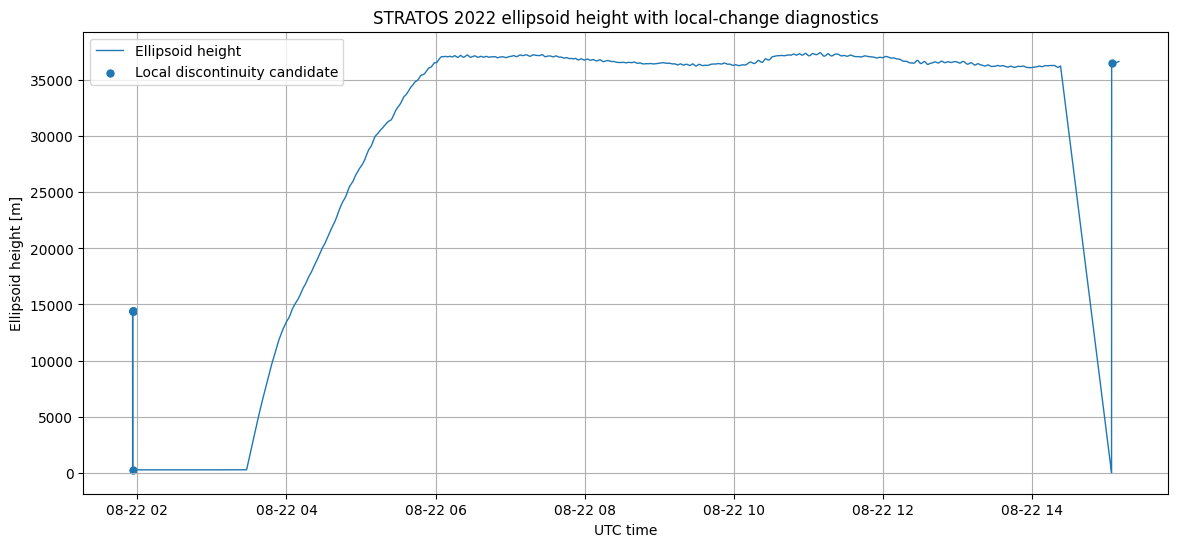

In [13]:
flagged_altitude = altitude_diagnostics_2022[
    altitude_diagnostics_2022["altitude_anomaly_candidate"]
]

plt.figure(figsize=(14, 6))
plt.plot(
    altitude_diagnostics_2022["parsed_timestamp"],
    altitude_diagnostics_2022["altitude_numeric"],
    linewidth=1,
    label="Ellipsoid height",
)
plt.scatter(
    flagged_altitude["parsed_timestamp"],
    flagged_altitude["altitude_numeric"],
    s=25,
    label="Local discontinuity candidate",
)
plt.xlabel("UTC time")
plt.ylabel("Ellipsoid height [m]")
plt.title(
    "STRATOS 2022 ellipsoid height with local-change diagnostics"
)
plt.legend()
plt.grid(True)
plt.show()


### Inspect the sudden 10,000+ m block with surrounding rows

This view includes timestamp, coordinates, altitude, and available GNSS
validity fields. A simultaneous position jump and altitude jump is
stronger evidence of an invalid or stale navigation solution than
altitude alone.

In [14]:
candidate_indices = altitude_candidates_2022.index.to_list()

if not candidate_indices:
    print("No altitude candidates were detected with the current thresholds.")
else:
    context_start = max(0, min(candidate_indices) - 8)
    context_end = min(
        len(altitude_diagnostics_2022) - 1,
        max(candidate_indices) + 8,
    )

    display(
        altitude_diagnostics_2022.loc[
            context_start:context_end,
            candidate_columns,
        ]
    )


,original_data_index,original_csv_row,parsed_timestamp,latitude_numeric,longitude_numeric,altitude_numeric,time_step_s,valid_consecutive_step,altitude_step_m,altitude_rate_mps,rolling_altitude_median_m,local_altitude_residual_m,sudden_altitude_transition,temporary_altitude_segment,lat_lon_valid_flag
0,0,3,2022-08-22 01:56:02.500000+00:00,0.000000,0.000000,0.000,NaN,False,NaN,NaN,0.000,0.000,False,False,False
1,1,4,2022-08-22 01:56:03.500000+00:00,0.000000,0.000000,0.000,1.0,True,0.000,0.000,0.000,0.000,False,False,False
2,2,5,2022-08-22 01:56:04.500000+00:00,0.000000,0.000000,0.000,1.0,True,0.000,0.000,0.000,0.000,False,False,False
3,3,6,2022-08-22 01:56:05.500000+00:00,0.000000,0.000000,0.000,1.0,True,0.000,0.000,0.000,0.000,False,False,False
4,4,7,2022-08-22 01:56:06.500000+00:00,0.000000,0.000000,0.000,1.0,True,0.000,0.000,0.000,0.000,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44836,44845,44848,2022-08-22 15:04:14.500000+00:00,48.948595,-83.052503,36569.997,1.0,True,0.496,0.496,36570.456,0.459,False,False,False
44837,44846,44849,2022-08-22 15:04:15.500000+00:00,48.948679,-83.052565,36570.504,1.0,True,0.507,0.507,36570.504,0.000,False,False,False
44838,44847,44850,2022-08-22 15:04:16.500000+00:00,48.948764,-83.052628,36571.012,1.0,True,0.508,0.508,36571.012,0.000,False,False,True
44839,44848,44851,2022-08-22 15:04:17.500000+00:00,48.948849,-83.052690,36571.493,1.0,True,0.481,0.481,36571.493,0.000,False,False,False


## 11. Detect spatial discontinuities and build the final trajectory

The initially cleaned trajectory is split whenever consecutive positions
differ by more than 100 km. The segment summary is displayed before the final
selection.


In [15]:
trajectory_segmented_2022, segment_summary_2022 = (
    segment_trajectory_by_position_jump(
        trajectory_2022_initial,
        threshold_m=POSITION_JUMP_THRESHOLD_M,
    )
)

trajectory_segmented_2022["position_step_km"] = (
    trajectory_segmented_2022["position_step_m"] / 1000
)
trajectory_segmented_2022["time_step_s"] = (
    trajectory_segmented_2022["timestamp"]
    .diff()
    .dt.total_seconds()
)
trajectory_segmented_2022["horizontal_speed_mps"] = (
    trajectory_segmented_2022["position_step_m"]
    / trajectory_segmented_2022["time_step_s"].replace(0, np.nan)
)

spatial_jump_candidates_2022 = trajectory_segmented_2022[
    trajectory_segmented_2022["position_step_m"]
    > POSITION_JUMP_THRESHOLD_M
].copy()

print(
    "Consecutive position jumps greater than "
    f"{POSITION_JUMP_THRESHOLD_M / 1000:.0f} km:",
    len(spatial_jump_candidates_2022),
)

display(
    spatial_jump_candidates_2022[
        [
            "original_data_index",
            "original_csv_row",
            "timestamp",
            "latitude",
            "longitude",
            "altitude_m",
            "position_step_km",
            "time_step_s",
            "horizontal_speed_mps",
            "segment_id",
        ]
    ]
)

print("Trajectory segment summary:")
display(segment_summary_2022)

for bad_index in spatial_jump_candidates_2022.index:
    start = max(0, bad_index - 6)
    end = min(
        len(trajectory_segmented_2022) - 1,
        bad_index + 6,
    )

    print("\n" + "=" * 110)

    display(
        trajectory_segmented_2022.loc[
            start:end,
            [
                "original_data_index",
                "original_csv_row",
                "timestamp",
                "latitude",
                "longitude",
                "altitude_m",
                "position_step_km",
                "time_step_s",
                "segment_id",
            ],
        ]
    )

if segment_summary_2022.empty:
    raise RuntimeError("No trajectory segments are available.")

if AUTO_SELECT_LARGEST_SEGMENT:
    SELECTED_SEGMENT_ID = int(
        segment_summary_2022.iloc[0]["segment_id"]
    )
else:
    # Change this value after inspecting segment_summary_2022.
    SELECTED_SEGMENT_ID = 0

print("Selected segment ID:", SELECTED_SEGMENT_ID)

final_trajectory_2022 = (
    trajectory_segmented_2022[
        trajectory_segmented_2022["segment_id"]
        == SELECTED_SEGMENT_ID
    ]
    .drop(
        columns=[
            "position_step_m",
            "new_segment",
            "segment_id",
            "position_step_km",
            "time_step_s",
            "horizontal_speed_mps",
        ],
        errors="ignore",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Initial cleaned rows:", len(trajectory_2022_initial))
print("Final spatially cleaned rows:", len(final_trajectory_2022))
print("Final time range:")
print(final_trajectory_2022["timestamp"].min())
print(final_trajectory_2022["timestamp"].max())

display(
    final_trajectory_2022["timestamp"]
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

assert not final_trajectory_2022.empty
assert final_trajectory_2022["timestamp"].dt.year.eq(YEAR).all()
assert ~(
    (final_trajectory_2022["latitude"] == 0)
    & (final_trajectory_2022["longitude"] == 0)
).any()


Consecutive position jumps greater than 100 km: 1


,original_data_index,original_csv_row,timestamp,latitude,longitude,altitude_m,position_step_km,time_step_s,horizontal_speed_mps,segment_id
4,12,15,2022-08-22 01:56:14.500000+00:00,48.569581,-81.37089,257.751,1831.794711,1.0,1.831795e+06,1


Trajectory segment summary:


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,1,45165,2022-08-22 01:56:14.500000+00:00,2022-08-22 15:10:01.500000+00:00,48.325383,48.978127,-83.070859,-81.131268,255.946,37446.743
1,0,4,2022-08-22 01:56:10.500000+00:00,2022-08-22 01:56:13.500000+00:00,55.265141,55.431333,-105.920893,-105.576722,14402.818,14461.015


,original_data_index,original_csv_row,timestamp,latitude,longitude,altitude_m,position_step_km,time_step_s,segment_id
0,8,11,2022-08-22 01:56:10.500000+00:00,55.431333,-105.920893,14461.015,NaN,NaN,0
1,9,12,2022-08-22 01:56:11.500000+00:00,55.430806,-105.914565,14460.830,0.403536,1.0,0
2,10,13,2022-08-22 01:56:12.500000+00:00,55.265141,-105.576722,14402.818,28.206013,1.0,0
3,11,14,2022-08-22 01:56:13.500000+00:00,55.429750,-105.901910,14460.461,27.527087,1.0,0
4,12,15,2022-08-22 01:56:14.500000+00:00,48.569581,-81.370890,257.751,1831.794711,1.0,1
5,13,16,2022-08-22 01:56:15.500000+00:00,48.569600,-81.370892,258.647,0.002084,1.0,1
6,14,17,2022-08-22 01:56:16.500000+00:00,48.569601,-81.370887,258.638,0.000391,1.0,1
7,15,18,2022-08-22 01:56:17.500000+00:00,48.569602,-81.370884,258.519,0.000245,1.0,1
8,16,19,2022-08-22 01:56:18.500000+00:00,48.569638,-81.370736,258.522,0.011642,1.0,1
9,17,20,2022-08-22 01:56:19.500000+00:00,48.569687,-81.370553,257.965,0.014493,1.0,1


Selected segment ID: 1
Initial cleaned rows: 45169
Final spatially cleaned rows: 45165
Final time range:
2022-08-22 01:56:14.500000+00:00
2022-08-22 15:10:01.500000+00:00


,year,rows
0,2022,45165


## 12. Visualize the final cleaned trajectory

The same `final_trajectory_2022` dataframe is used for both plots and the
final trajectory CSV export.


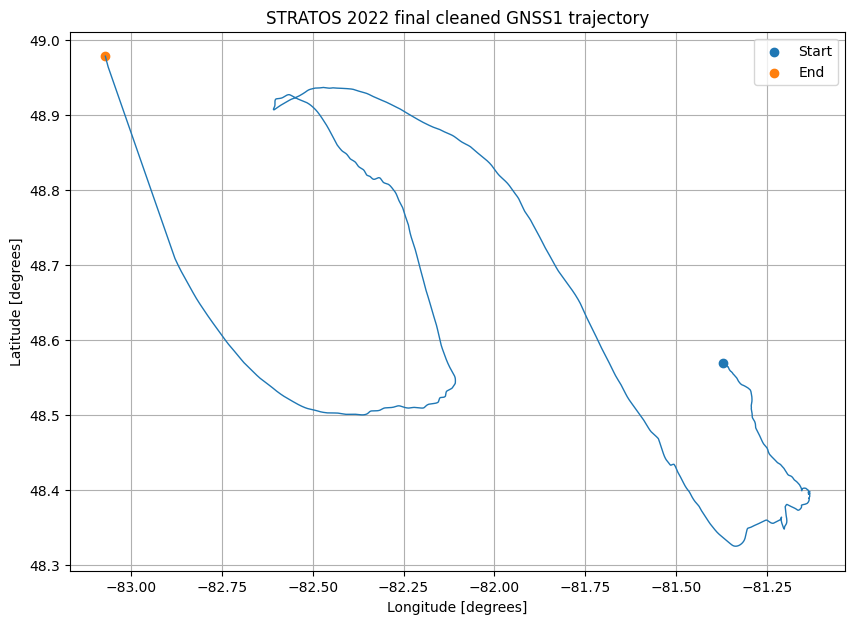

In [16]:
plot_2d_trajectory(
    final_trajectory_2022,
    title="STRATOS 2022 final cleaned GNSS1 trajectory",
)

plot_3d_trajectory(
    final_trajectory_2022,
    title="STRATOS 2022 final cleaned 3D trajectory",
)


## 13. Inspect IMU temperature and pressure

IMU timestamp counts by year:


,year,rows
0,1980,20
1,2022,45138


IMU rows outside 2022: 20


,Source,UTC Timestamp,Packet,Scaled Accel X,Scaled Accel Y,Scaled Accel Z,Scaled Gyro X,Scaled Gyro Y,Scaled Gyro Z,Scaled Magnetometer X,Scaled Magnetometer Y,Scaled Magnetometer Z,CF q0,CF q1,CF q2,CF q3,CF Roll,CF Pitch,CF Yaw,GPS TOW,GPS Week Num,GPS Time Valid,Min Temp,Max Temp,Mean Temp,Pressure,parsed_timestamp,timestamp_year
44790,LOGQ7,1980-01-06 00:00:05.124,GQ7_IMU,-0.018250152468681335,0.004820103757083416,-0.9891118407249451,-0.00013544151443056762,9.608503751223907e-05,9.582441271049902e-05,-0.03863045573234558,0.10093069076538086,0.6092184782028198,0.9767305850982666,0.00023115490330383182,0.0016946542309597135,-0.21446341276168823,-0.06751970163802883,-0.18399385033719845,24.768244977778245,5.124,0,0,68.20442199707031,68.75690460205078,68.4254150390625,-0.6732909083366394,1980-01-06 00:00:05.124000+00:00,1980
44791,LOGQ7,1980-01-06 00:00:06.124,GQ7_IMU,-0.018210262060165405,0.004846387542784214,-0.988849401473999,-0.00018033197557087988,-5.4942163842497393e-05,3.840229692286812e-05,-0.0384395532310009,0.10219620913267136,0.6092610359191895,0.9423218369483948,1.9471728592179716e-05,0.0024698448833078146,-0.33469927310943604,-0.09683140510028565,-0.26595329225214825,39.10885722517095,6.124,0,0,68.20442199707031,68.75690460205078,68.4254150390625,-0.6645197868347168,1980-01-06 00:00:06.124000+00:00,1980
44792,LOGQ7,1980-01-06 00:00:07.124,GQ7_IMU,-0.01820291206240654,0.004903403110802174,-0.9888186454772949,-6.963831401662901e-05,0.00010905879753408954,-2.587212975413422e-06,-0.03957835212349892,0.10104242712259293,0.6100075244903564,0.8867823481559753,-0.0004224732983857393,0.0030919774435460567,-0.4621767997741699,-0.12082732707799494,-0.33657659449643385,55.05597606912755,7.124,0,0,68.20442199707031,68.75690460205078,68.5359115600586,-0.6702150702476501,1980-01-06 00:00:07.124000+00:00,1980
44793,LOGQ7,1980-01-06 00:00:08.124,GQ7_IMU,-0.018275819718837738,0.004831047262996435,-0.9886506795883179,-0.00023275976127479225,1.3536897313315421e-05,0.00011115530651295558,-0.03802260011434555,0.10200820118188858,0.6092649102210999,0.8293473124504089,-0.0009647849947214127,0.0036361035890877247,-0.5587207078933716,-0.14111456305809308,-0.4073349263789594,67.93579356061483,8.124,0,0,68.20442199707031,68.86740112304688,68.5359115600586,-0.634149968624115,1980-01-06 00:00:08.124000+00:00,1980
44794,LOGQ7,1980-01-06 00:00:09.124,GQ7_IMU,-0.018184199929237366,0.004787207581102848,-0.9885809421539307,-7.057042967062443e-05,4.1901519580278546e-05,7.597621151944622e-05,-0.03813883289694786,0.10332299768924713,0.61048823595047,0.8287874460220337,-0.0011440779780969024,0.004170533735305071,-0.559546947479248,-0.15876203764568708,-0.4694469591437629,68.0503221726176,9.124,0,0,68.20442199707031,68.9779052734375,68.86740112304688,-0.6249372959136963,1980-01-06 00:00:09.124000+00:00,1980
44795,LOGQ7,1980-01-06 00:00:10.124,GQ7_IMU,-0.01823824644088745,0.004830982536077499,-0.9884774088859558,-7.547829591203481e-05,-2.1571682736976072e-05,0.00020872503228019923,-0.03738826885819435,0.10293100029230118,0.6109728813171387,0.831881046295166,-0.0012506309431046247,0.004667703062295914,-0.5549329519271851,-0.17761161218699012,-0.524491773830013,67.41389880613416,10.124,0,0,68.20442199707031,68.9779052734375,68.75690460205078,-0.6325405240058899,1980-01-06 00:00:10.124000+00:00,1980
44796,LOGQ7,1980-01-06 00:00:11.124,GQ7_IMU,-0.018254050984978676,0.004912946373224258,-0.9884796142578125,-0.00019044423243030906,6.181671778904274e-05,0.0001521586236776784,-0.03735722601413727,0.10322904586791992,0.6091229915618896,0.8314959406852722,-0.0013486029347404838,0.005131933838129044,-0.5555055737495422,-0.19819187929073767,-0.5748397662448215,67.49316998164132,11.124,0,0,68.20442199707031,69.08839416503906,68.86740112304688,-0.6246106624603271,1980-01-06 00:00:11.124000+00:00,1980
44797,LOGQ7,1980-01-06 00:00:12.124,GQ7_IMU,-0.018265720456838608,0.004794161766767502,-0.9883968830108643,-0.00012914041872136295,-5.196156780584715e-05,0.00011841187370

Filtered IMU time range:
2022-08-22 01:56:26.763000+00:00
2022-08-22 15:10:01.800000+00:00
Available IMU fields: {'Minimum temperature [°C]': 'Min Temp', 'Maximum temperature [°C]': 'Max Temp', 'Mean temperature [°C]': 'Mean Temp', 'Pressure [mbar]': 'Pressure'}


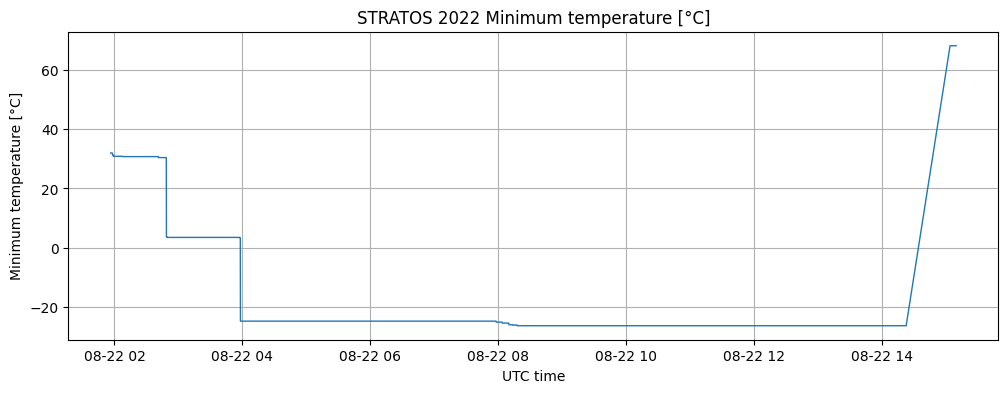

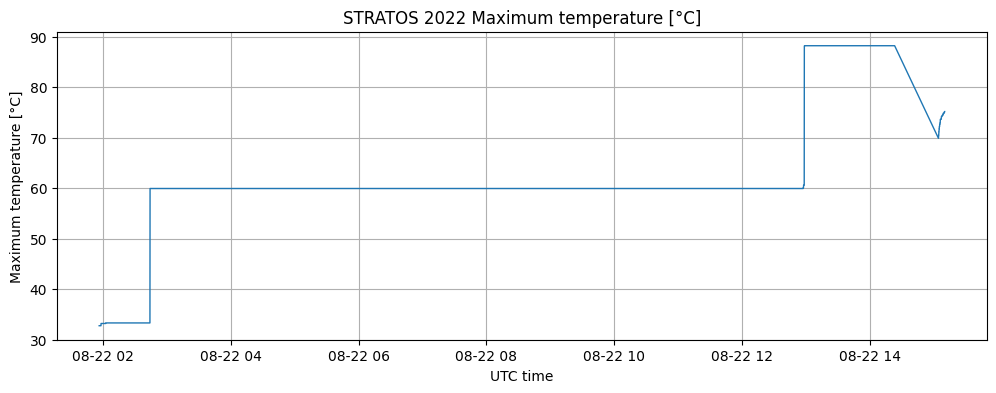

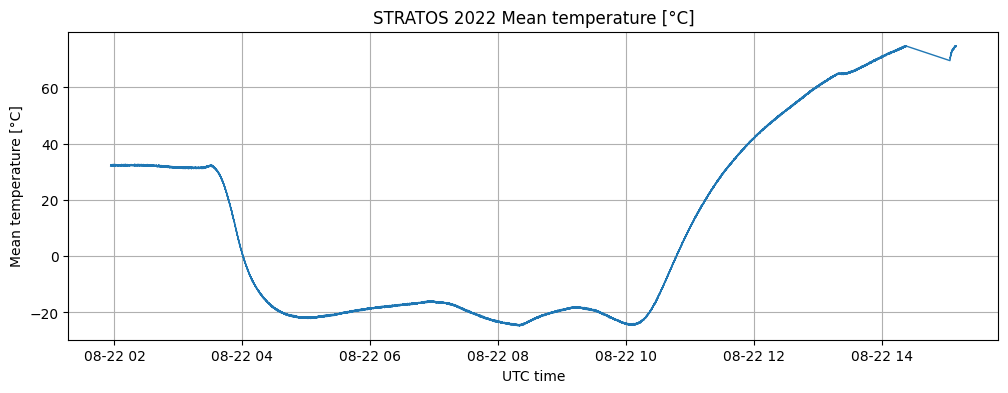

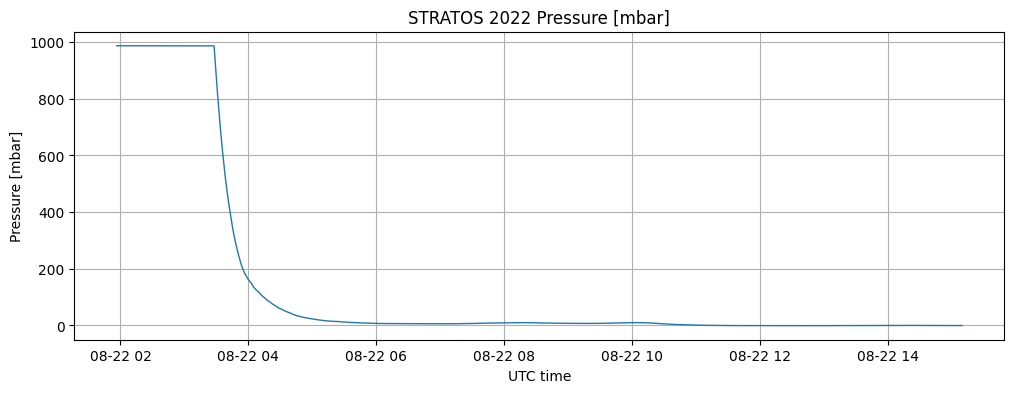

In [17]:
imu_raw = imu.copy()

imu_time_col = find_column(
    imu_raw,
    ["UTC Timestamp", "Timestamp"],
    required=True,
)

imu_raw["parsed_timestamp"] = parse_campaign_timestamp(
    imu_raw[imu_time_col],
    flight_date=FLIGHT_DATE,
)
imu_raw["timestamp_year"] = imu_raw["parsed_timestamp"].dt.year

imu_timestamp_anomalies_2022 = imu_raw[
    imu_raw["parsed_timestamp"].notna()
    & (imu_raw["timestamp_year"] != YEAR)
].copy()

print("IMU timestamp counts by year:")
display(
    imu_raw["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

print(
    "IMU rows outside 2022:",
    len(imu_timestamp_anomalies_2022),
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(imu_timestamp_anomalies_2022)

imu_2022 = (
    imu_raw[
        imu_raw["parsed_timestamp"].notna()
        & (imu_raw["timestamp_year"] == YEAR)
    ]
    .sort_values("parsed_timestamp")
    .reset_index(drop=True)
)

print("Filtered IMU time range:")
print(imu_2022["parsed_timestamp"].min())
print(imu_2022["parsed_timestamp"].max())

imu_field_candidates = {
    "Minimum temperature [°C]": [
        "Min Temp",
        "Minimum Temp",
    ],
    "Maximum temperature [°C]": [
        "Max Temp",
        "Maximum Temp",
    ],
    "Mean temperature [°C]": [
        "Mean Temp",
        "Mean Temperature",
    ],
    "Pressure [mbar]": [
        "Pressure",
    ],
}

imu_plot_columns: dict[str, str] = {}

for label, candidates in imu_field_candidates.items():
    column = find_column(
        imu_2022,
        candidates,
        required=False,
    )

    if column is not None:
        imu_plot_columns[label] = column
        imu_2022[column] = numeric(imu_2022[column])

print("Available IMU fields:", imu_plot_columns)

for label, column in imu_plot_columns.items():
    plot_data = imu_2022[
        ["parsed_timestamp", column]
    ].dropna()

    plt.figure(figsize=(12, 4))
    plt.plot(
        plot_data["parsed_timestamp"],
        plot_data[column],
        linewidth=1,
    )
    plt.xlabel("UTC time")
    plt.ylabel(label)
    plt.title(f"STRATOS 2022 {label}")
    plt.grid(True)
    plt.show()


## 14. Inspect track angle

Track-angle timestamp counts by year:


,year,rows
0,2022,45185


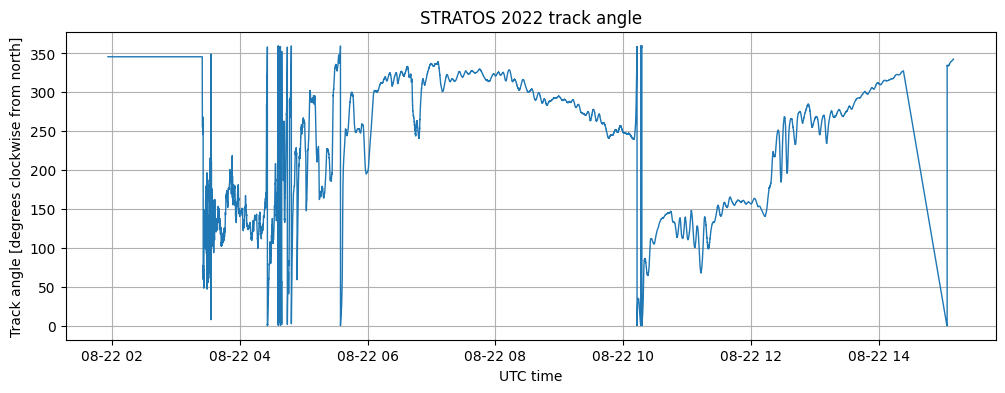

,validity value,rows
0,1,38668
1,0,6517


In [18]:
track_raw = track.copy()

track_time_col = find_column(
    track_raw,
    ["UTC Timestamp", "Timestamp"],
    required=True,
)
track_angle_col = find_column(
    track_raw,
    ["Track Angle"],
    required=True,
)
track_valid_col = find_column(
    track_raw,
    ["Track Angle Valid"],
    required=False,
)

track_raw["parsed_timestamp"] = parse_campaign_timestamp(
    track_raw[track_time_col],
    flight_date=FLIGHT_DATE,
)
track_raw["timestamp_year"] = track_raw["parsed_timestamp"].dt.year
track_raw["track_angle_numeric"] = numeric(
    track_raw[track_angle_col]
)

track_timestamp_anomalies_2022 = track_raw[
    track_raw["parsed_timestamp"].notna()
    & (track_raw["timestamp_year"] != YEAR)
].copy()

print("Track-angle timestamp counts by year:")
display(
    track_raw["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

track_2022 = (
    track_raw[
        track_raw["parsed_timestamp"].notna()
        & (track_raw["timestamp_year"] == YEAR)
    ]
    .sort_values("parsed_timestamp")
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 4))
plt.plot(
    track_2022["parsed_timestamp"],
    track_2022["track_angle_numeric"],
    linewidth=1,
)
plt.xlabel("UTC time")
plt.ylabel("Track angle [degrees clockwise from north]")
plt.title("STRATOS 2022 track angle")
plt.grid(True)
plt.show()

if track_valid_col is not None:
    display(
        track_2022[track_valid_col]
        .value_counts(dropna=False)
        .rename_axis("validity value")
        .reset_index(name="rows")
    )


## 15. Image directory inspection

In 2022, camera `0` is horizon-facing and camera `1` is nadir-facing.
This cell indexes image links without downloading every image.

In [19]:
RUN_IMAGE_INDEX = False

if RUN_IMAGE_INDEX:
    html = fetch_text(IMAGE_BASE_URL)
    hrefs = re.findall(r'href=["\']([^"\']+)["\']', html, flags=re.I)
    image_urls = sorted(
        {
            urljoin(IMAGE_BASE_URL, href)
            for href in hrefs
            if href.lower().endswith((".jpg", ".jpeg"))
        }
    )

    image_index_rows = []
    for image_url in image_urls:
        filename = Path(image_url).name
        match = re.match(
            r"(?P<camera>\d+)_(?P<date>\d{8})_(?P<time>\d{6})\.jpe?g$",
            filename,
            flags=re.I,
        )
        if not match:
            continue

        image_index_rows.append(
            {
                "camera_id": match.group("camera"),
                "camera_label": {
                    "0": "Horizon",
                    "1": "Nadir",
                }.get(match.group("camera"), "Unknown"),
                "timestamp": pd.to_datetime(
                    match.group("date") + match.group("time"),
                    format="%Y%m%d%H%M%S",
                    utc=True,
                ),
                "filename": filename,
                "url": image_url,
            }
        )

    image_index = pd.DataFrame(image_index_rows)
    print("Indexed images:", len(image_index))
    display(image_index.head(20))
else:
    print("Set RUN_IMAGE_INDEX = True to index the 2022 image directory.")

Set RUN_IMAGE_INDEX = True to index the 2022 image directory.


## 16. Export final cleaned data and diagnostics

The final trajectory CSV is created from `final_trajectory_2022`, which is
the same dataframe used in the final 2D and 3D plots.


In [21]:
OUTPUT_DIR = Path("tutorial_outputs_2022")
OUTPUT_DIR.mkdir(exist_ok=True)

export_files = {
    "final_trajectory": (
        final_trajectory_2022,
        OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2022.csv",
    ),
    "timestamp_anomalies": (
        rows_outside_2022,
        OUTPUT_DIR / "gnss1_timestamp_anomalies_2022.csv",
    ),
    "altitude_candidates": (
        altitude_candidates_2022,
        OUTPUT_DIR / "gnss1_altitude_anomaly_candidates_2022.csv",
    ),
    "spatial_jump_candidates": (
        spatial_jump_candidates_2022,
        OUTPUT_DIR / "gnss1_spatial_jump_candidates_2022.csv",
    ),
    "trajectory_segments": (
        segment_summary_2022,
        OUTPUT_DIR / "gnss1_trajectory_segments_2022.csv",
    ),
    "imu_timestamp_anomalies": (
        imu_timestamp_anomalies_2022,
        OUTPUT_DIR / "imu_timestamp_anomalies_2022.csv",
    ),
    "imu_cleaned": (
        imu_2022,
        OUTPUT_DIR / "imu_cleaned_2022.csv",
    ),
    "track_timestamp_anomalies": (
        track_timestamp_anomalies_2022,
        OUTPUT_DIR / "track_angle_timestamp_anomalies_2022.csv",
    ),
    "track_cleaned": (
        track_2022,
        OUTPUT_DIR / "track_angle_cleaned_2022.csv",
    ),
}

export_summary_rows = []

for label, (frame, path) in export_files.items():
    frame.to_csv(path, index=False)

    export_summary_rows.append(
        {
            "export": label,
            "rows": len(frame),
            "columns": len(frame.columns),
            "path": str(path.resolve()),
        }
    )

export_summary = pd.DataFrame(export_summary_rows)
display(export_summary)

final_export_path = (
    OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2022.csv"
)
final_export_check = pd.read_csv(final_export_path)

assert len(final_export_check) == len(final_trajectory_2022)
assert final_trajectory_2022["timestamp"].dt.year.eq(YEAR).all()
assert ~(
    (final_trajectory_2022["latitude"] == 0)
    & (final_trajectory_2022["longitude"] == 0)
).any()

print("Final consistency checks passed.")
print("Saved files to:", OUTPUT_DIR.resolve())
print("Final trajectory rows:", len(final_trajectory_2022))
print("Exported trajectory rows:", len(final_export_check))


,export,rows,columns,path
0,final_trajectory,45165,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\gnss...
1,timestamp_anomalies,9,65,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\gnss...
2,altitude_candidates,6,75,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\gnss...
3,spatial_jump_candidates,1,13,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\gnss...
4,trajectory_segments,2,10,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\gnss...
5,imu_timestamp_anomalies,20,28,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\imu_...
6,imu_cleaned,45138,28,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\imu_...
7,track_timestamp_anomalies,0,8,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\trac...
8,track_cleaned,45185,8,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022\trac...


Final consistency checks passed.
Saved files to: C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2022
Final trajectory rows: 45165
Exported trajectory rows: 45165


## Conclusions

- The source CSV files remain unchanged for traceability.
- GPS-epoch timestamps are reported and excluded only from derived
  campaign-year views.
- `(0°, 0°)` GNSS placeholders do not define the flight origin.
- The early spatially discontinuous navigation segment is isolated through
  trajectory segmentation rather than geographic hard-coding.
- Altitude candidates are based on abrupt local transitions, short temporary
  blocks, local disagreement, and valid sampling gaps.
- IMU and track-angle plots use only 2022 timestamps.
- `final_trajectory_2022` is used consistently for the final 2D plot, final
  3D plot, and final trajectory CSV export.
- All anomaly tables remain available for audit and further scientific review.
